In [2]:
%load_ext autoreload
%autoreload 2

import torch
from torch import nn
from torch.nn import functional as F

import matplotlib.pyplot as plt
import numpy as np

from src.utils import DEVICE, CKPT_DIR, FIG_DIR, set_seed, save_history, load_history, show_grid
from src.data import get_dataloaders, CLASSES
from src.metrics import recon_metrics, latency_ms
from src.train import train_classifier, evaluate_classifier, extract_latents, fit

 ### Dataset Preparation

In [ ]:
set_seed(42) # random, numpy, torch

BATCH_SIZE = 256
EPOCHS = 20

# 70k samples (train 60k + test 10k), stratified split 80:10:10
# batch 256, shuffle=True for train and shuffle=False for validation/test
train_dl, val_dl, test_dl = get_dataloaders(batch_size=BATCH_SIZE)

print(len(train_dl.dataset), len(val_dl.dataset), len(test_dl.dataset))
print(DEVICE)

56000 7000 7000
cuda


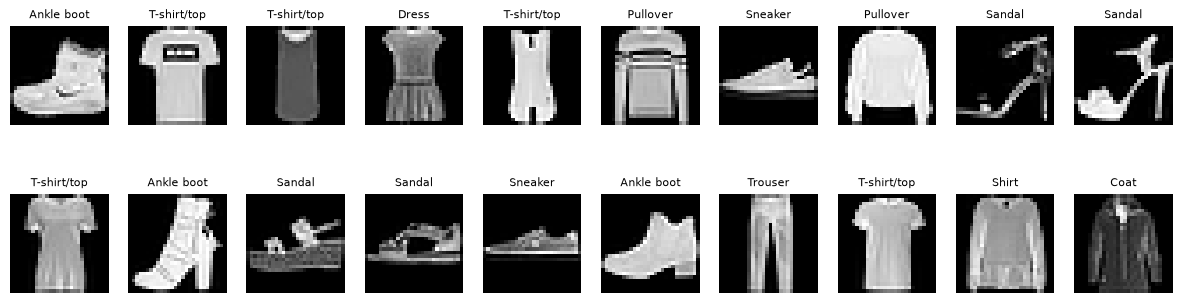

In [4]:
# test show image
x = train_dl.dataset.dataset.datasets[0].data
classes = train_dl.dataset.dataset.datasets[0].classes
y_idx = train_dl.dataset.dataset.datasets[0].targets
y = [classes[i] for i in y_idx]

sample_x, sample_y = x[:20], y[:20]

fig, axes = plt.subplots(2, 10, figsize=(15, 4))
for c, ax in enumerate(axes.flat):
    ax.imshow(sample_x[c].numpy(), cmap="gray")
    ax.set_title(sample_y[c], fontsize=8)
    ax.axis("off")
plt.show()

MLP: step 1 (train classifier)

In [5]:
# base MLP model to recreate encoder architecture: 784 -> 256 -> 64 -> 10
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)  # (B,1,28,28) -> (B,784) flatten
        h = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h))    # latent
        return self.fc3(z), z      # logits, z

In [6]:
# Train, Validate, Test
set_seed(42)
model = MLP().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0)

history = train_classifier("mlp", model, opt, train_dl, val_dl, epochs=EPOCHS)

test_loss, test_acc = evaluate_classifier(model, test_dl)
print("Test Loss    :", test_loss)
print("Test Accuracy:", test_acc)

Epoch   1: train_loss=0.6765 | train_acc=0.7708 | val_loss=0.4835 | val_acc=0.8289 | 4.3s
Epoch   2: train_loss=0.4343 | train_acc=0.8473 | val_loss=0.4201 | val_acc=0.8491 | 4.0s
Epoch   3: train_loss=0.3922 | train_acc=0.8613 | val_loss=0.3978 | val_acc=0.8551 | 5.2s
Epoch   4: train_loss=0.3600 | train_acc=0.8701 | val_loss=0.3765 | val_acc=0.8626 | 5.0s
Epoch   5: train_loss=0.3410 | train_acc=0.8769 | val_loss=0.3595 | val_acc=0.8693 | 4.9s
Epoch   6: train_loss=0.3255 | train_acc=0.8824 | val_loss=0.3527 | val_acc=0.8733 | 4.9s
Epoch   7: train_loss=0.3107 | train_acc=0.8869 | val_loss=0.3401 | val_acc=0.8771 | 5.1s
Epoch   8: train_loss=0.2954 | train_acc=0.8908 | val_loss=0.3525 | val_acc=0.8706 | 5.1s
Epoch   9: train_loss=0.2922 | train_acc=0.8930 | val_loss=0.3340 | val_acc=0.8789 | 4.8s
Epoch  10: train_loss=0.2776 | train_acc=0.8987 | val_loss=0.3343 | val_acc=0.8810 | 5.0s
Epoch  11: train_loss=0.2692 | train_acc=0.9015 | val_loss=0.3288 | val_acc=0.8777 | 5.2s
Epoch  12:

In [7]:
# save weights (for Step 2-3)
W1 = model.fc1.weight.detach()   # (256, 784)
W2 = model.fc2.weight.detach()   # (64, 256)
W3 = model.fc3.weight.detach()   # (10, 64)
torch.save({"W1": W1.cpu(), "W2": W2.cpu(), "W3": W3.cpu()}, CKPT_DIR / "mlp_weights.pt")

# save z_mlp of the test set (for Step 3-5)
z_mlp, y_test = extract_latents(model, test_dl)   # (7000, 64), (7000,)
torch.save({"z": z_mlp, "y": y_test}, CKPT_DIR / "z_mlp.pt")
print(W1.shape, W2.shape, W3.shape, z_mlp.shape)

torch.Size([256, 784]) torch.Size([64, 256]) torch.Size([10, 64]) torch.Size([7000, 64])


MLP: Step 2 (Top-Down Weight Transportation -> reverse from one hot to pixels)

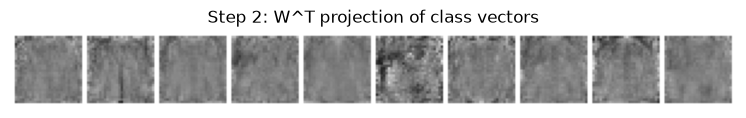

In [10]:
Y = torch.eye(10, device=W3.device) # 10 sample one hot 1 per class

z_hat  = F.relu(Y @ W3)             # (10,10) @ (10,64)   -> (10,64)  
h1_hat = F.relu(z_hat @ W2)         # (10,64) @ (64,256)  -> (10,256) 
x_hat  = torch.sigmoid(h1_hat @ W1) # (10,256) @ (256,784)-> (10,784) 

show_grid(x_hat.view(10, 1, 28, 28), nrow=10, title="Step 2: W^T projection of class vectors")

MLP: Step 3 (reverse latent to pixels)

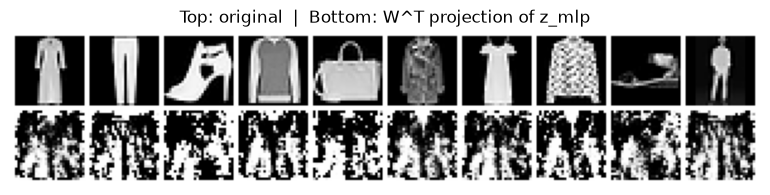

In [11]:
x_test, y_lbl = next(iter(test_dl)) # first test batch, same order as z_mlp
x_orig = x_test[:10].to(W2.device)  # (10,1,28,28)
z = z_mlp[:10].to(W2.device)        # (10,64), z of exactly those 10 images

h1_back = F.relu(z @ W2)            # (10,64) @ (64,256)  -> (10,256)
x_back = torch.sigmoid(h1_back @ W1)# (10,256) @ (256,784) -> (10,784)

show_grid(torch.cat([x_orig, x_back.view(10, 1, 28, 28)]), nrow=10,
          title="Top: original  |  Bottom: W^T projection of z_mlp")

MLP: Step 4 part 1 (frozen mlp classifier + decoder)

In [12]:
# 64 -> 256 -> 784
class Decoder(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid())
    def forward(self, z):
        return self.net(z)

In [13]:
def frozen_dec_loss(decoder, x, y):
    with torch.no_grad():
        _, z = model(x) # get latent space from encoder
    x_hat = decoder(z)  # get reconstructed pixels
    return F.mse_loss(x_hat, x.view(x.size(0), -1))

# freeze encoder weights
for p in model.parameters():
    p.requires_grad = False
model.eval()

set_seed(42)
decoder = Decoder().to(DEVICE)
opt_dec = torch.optim.Adam(decoder.parameters(), lr=1e-3)

# train, validate, and eval
hist_dec = fit("mlp_frozen_decoder", decoder, frozen_dec_loss, opt_dec, train_dl, val_dl, epochs=EPOCHS)
res_mlp_dec = recon_metrics(lambda x: decoder(model(x)[1]))

mlp_frozen_decoder ep   1 | train 0.04146 | val 0.02791 | 5.7s
mlp_frozen_decoder ep   2 | train 0.02558 | val 0.02370 | 5.8s
mlp_frozen_decoder ep   3 | train 0.02260 | val 0.02216 | 5.6s
mlp_frozen_decoder ep   4 | train 0.02112 | val 0.02061 | 5.6s
mlp_frozen_decoder ep   5 | train 0.02024 | val 0.01999 | 5.5s
mlp_frozen_decoder ep   6 | train 0.01961 | val 0.01943 | 4.5s
mlp_frozen_decoder ep   7 | train 0.01914 | val 0.01910 | 5.5s
mlp_frozen_decoder ep   8 | train 0.01876 | val 0.01864 | 4.9s
mlp_frozen_decoder ep   9 | train 0.01845 | val 0.01836 | 5.7s
mlp_frozen_decoder ep  10 | train 0.01814 | val 0.01828 | 6.0s
mlp_frozen_decoder ep  11 | train 0.01789 | val 0.01796 | 5.6s
mlp_frozen_decoder ep  12 | train 0.01772 | val 0.01770 | 5.2s
mlp_frozen_decoder ep  13 | train 0.01749 | val 0.01758 | 4.9s
mlp_frozen_decoder ep  14 | train 0.01731 | val 0.01739 | 4.9s
mlp_frozen_decoder ep  15 | train 0.01717 | val 0.01724 | 5.6s
mlp_frozen_decoder ep  16 | train 0.01704 | val 0.01726

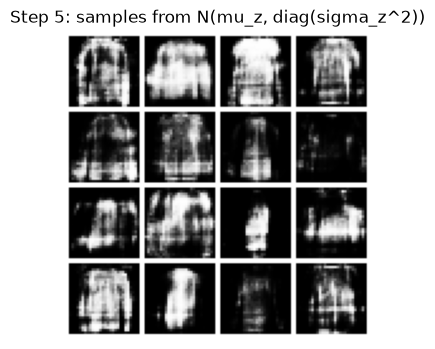

In [22]:
mu, sigma = z_mlp.mean(0), z_mlp.std(0) # per-dimension, shape (64,)
set_seed(42)
z_rand = (mu + sigma * torch.randn(16, 64)).to(DEVICE)
imgs = decoder(z_rand).view(16, 1, 28, 28)
show_grid(imgs, nrow=4, title="Step 5: samples from N(mu_z, diag(sigma_z^2))")

Vanilla Autoencoder 

In [15]:
# 784 -> 256 -> 64 -> 256 -> 784
class AE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Flatten(),                         # (B,1,28,28) -> (B,784)
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim), nn.ReLU())     # latent h, (B,64)
        self.dec = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid())    # pixels in [0,1], (B,784)

    def forward(self, x):
        h = self.enc(x)
        return self.dec(h), h # x_hat, latent

def ae_loss(model, x, y):
    x_hat, _ = model(x)
    return F.mse_loss(x_hat, x.flatten(1))

In [16]:
set_seed(42)
ae = AE().to(DEVICE)
opt_ae = torch.optim.Adam(ae.parameters(), lr=1e-3)
print("parameters:", sum(p.numel() for p in ae.parameters()))

# train and validate
hist_ae = fit("ae", ae, ae_loss, opt_ae, train_dl, val_dl, epochs=EPOCHS)

parameters: 435536
ae ep   1 | train 0.04663 | val 0.02386 | 3.8s
ae ep   2 | train 0.02125 | val 0.01926 | 5.3s
ae ep   3 | train 0.01810 | val 0.01725 | 4.6s
ae ep   4 | train 0.01633 | val 0.01565 | 4.5s
ae ep   5 | train 0.01502 | val 0.01453 | 4.5s
ae ep   6 | train 0.01406 | val 0.01383 | 4.5s
ae ep   7 | train 0.01334 | val 0.01309 | 4.8s
ae ep   8 | train 0.01278 | val 0.01256 | 5.3s
ae ep   9 | train 0.01233 | val 0.01231 | 4.9s
ae ep  10 | train 0.01189 | val 0.01178 | 5.1s
ae ep  11 | train 0.01158 | val 0.01159 | 4.9s
ae ep  12 | train 0.01132 | val 0.01127 | 4.6s
ae ep  13 | train 0.01102 | val 0.01100 | 4.7s
ae ep  14 | train 0.01082 | val 0.01079 | 4.6s
ae ep  15 | train 0.01059 | val 0.01072 | 4.7s
ae ep  16 | train 0.01040 | val 0.01052 | 4.5s
ae ep  17 | train 0.01021 | val 0.01022 | 4.5s
ae ep  18 | train 0.01008 | val 0.01013 | 4.7s
ae ep  19 | train 0.00993 | val 0.00998 | 4.6s
ae ep  20 | train 0.00977 | val 0.00981 | 4.6s


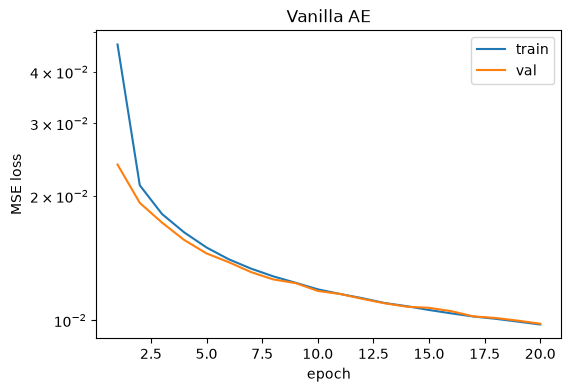

In [17]:
# loss curves 
ep = range(1, len(hist_ae["train_loss"]) + 1)
plt.figure(figsize=(6, 4))
plt.plot(ep, hist_ae["train_loss"], label="train")
plt.plot(ep, hist_ae["val_loss"], label="val")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("MSE loss")
plt.title("Vanilla AE")
plt.legend()
plt.savefig(FIG_DIR / "ae_loss.png", dpi=300, bbox_inches="tight")
plt.show()

z_ae, _ = extract_latents(ae, test_dl) 
torch.save({"z": z_ae, "y": y_test}, CKPT_DIR / "z_ae.pt")

MLP: Step 4 part 2 (compare with AE)

In [18]:
# reconstruction metrics, AE vs MLP frozen + decoder
ae.eval()
decoder.eval()

res_ae      = recon_metrics(lambda x: ae(x)[0])
res_mlp_dec = recon_metrics(lambda x: decoder(model(x)[1]))

x64 = next(iter(test_dl))[0][:64].to(DEVICE)
lat_ae = latency_ms(lambda: ae(x64)) # encode + decode, one batch of 64
time_ae = np.mean(hist_ae["epoch_time"])

print(f"{'':16}{'MSE':>9}{'PSNR':>9}{'SSIM':>8}")
print(f"{'Vanilla AE':16}{res_ae['mse']:9.5f}{res_ae['psnr']:9.2f}{res_ae['ssim']:8.4f}")
print(f"{'MLP + decoder':16}{res_mlp_dec['mse']:9.5f}{res_mlp_dec['psnr']:9.2f}{res_mlp_dec['ssim']:8.4f}")
print(f"train time/epoch: {time_ae:.2f} s | latency: {lat_ae:.3f} ms / batch 64")

                      MSE     PSNR    SSIM
Vanilla AE        0.00969    21.05  0.8053
MLP + decoder     0.01661    18.50  0.7029
train time/epoch: 4.69 s | latency: 0.131 ms / batch 64


[11, 1, 3, 0, 5, 8, 7, 20, 4, 2] tensor([[[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
     

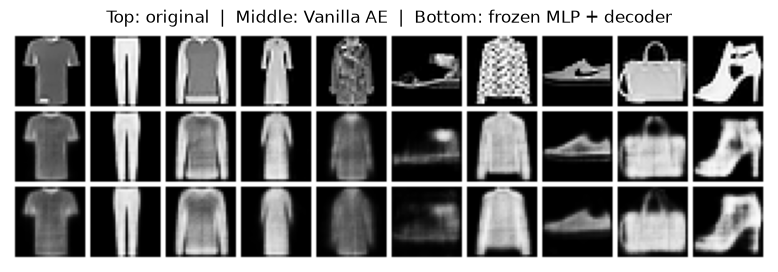

In [21]:
# one test image per class: original / Vanilla AE / MLP frozen decoder
x_all, y_all = next(iter(test_dl))
pick = [(y_all == c).nonzero()[0].item() for c in range(10)]
x_pick = x_all[pick].to(DEVICE) # (10,1,28,28)
print(pick, x_pick)

with torch.no_grad():
    rec_ae  = ae(x_pick)[0].view(-1, 1, 28, 28)
    rec_mlp = decoder(model(x_pick)[1]).view(-1, 1, 28, 28)

show_grid(torch.cat([x_pick, rec_ae, rec_mlp]), nrow=10,
          title="Top: original  |  Middle: Vanilla AE  |  Bottom: frozen MLP + decoder",
          path=FIG_DIR / "ae_vs_mlp_recon.png")

Sparse Autoencoder 

In [25]:
def make_sae_loss(lam):
    def sae_loss(m, x, y):
        x_hat, h = m(x)
        return F.mse_loss(x_hat, x.flatten(1)) + lam * h.abs().sum(dim=1).mean()
    return sae_loss

LAMS = [1e-5, 1e-4, 1e-3]
saes, hist_sae = {}, {}
for lam in LAMS:
    set_seed(42)
    sae = AE().to(DEVICE)
    opt_sae = torch.optim.Adam(sae.parameters(), lr=1e-3)
    hist_sae[lam] = fit(f"sae_lam{lam}", sae, make_sae_loss(lam), opt_sae, train_dl, val_dl, epochs=EPOCHS)
    saes[lam] = sae 

sae_lam1e-05 ep   1 | train 0.04693 | val 0.02436 | 4.6s
sae_lam1e-05 ep   2 | train 0.02159 | val 0.01955 | 4.4s
sae_lam1e-05 ep   3 | train 0.01829 | val 0.01724 | 4.4s
sae_lam1e-05 ep   4 | train 0.01628 | val 0.01552 | 4.4s
sae_lam1e-05 ep   5 | train 0.01492 | val 0.01448 | 4.3s
sae_lam1e-05 ep   6 | train 0.01398 | val 0.01366 | 4.5s
sae_lam1e-05 ep   7 | train 0.01328 | val 0.01305 | 4.5s
sae_lam1e-05 ep   8 | train 0.01278 | val 0.01253 | 4.3s
sae_lam1e-05 ep   9 | train 0.01224 | val 0.01215 | 4.4s
sae_lam1e-05 ep  10 | train 0.01187 | val 0.01177 | 4.5s
sae_lam1e-05 ep  11 | train 0.01152 | val 0.01149 | 4.4s
sae_lam1e-05 ep  12 | train 0.01124 | val 0.01123 | 4.4s
sae_lam1e-05 ep  13 | train 0.01096 | val 0.01093 | 4.4s
sae_lam1e-05 ep  14 | train 0.01073 | val 0.01078 | 4.5s
sae_lam1e-05 ep  15 | train 0.01052 | val 0.01056 | 4.4s
sae_lam1e-05 ep  16 | train 0.01035 | val 0.01036 | 4.3s
sae_lam1e-05 ep  17 | train 0.01015 | val 0.01020 | 4.3s
sae_lam1e-05 ep  18 | train 0.0

In [26]:
models = {"AE": ae, **{f"SAE lam={lam}": saes[lam] for lam in LAMS}}

for name, m in models.items():
    h, _ = extract_latents(m, test_dl)                  # (7000, 64): the latent h
    r = recon_metrics(lambda x: m(x)[0])
    print(f"{name:16} near-zero: {(h.abs() < 1e-3).float().mean():.3f} | "
          f"MSE {r['mse']:.5f} | SSIM {r['ssim']:.4f}")

AE               near-zero: 0.392 | MSE 0.00969 | SSIM 0.8053
SAE lam=1e-05    near-zero: 0.341 | MSE 0.00920 | SSIM 0.8134
SAE lam=0.0001   near-zero: 0.559 | MSE 0.01064 | SSIM 0.7829
SAE lam=0.001    near-zero: 1.000 | MSE 0.08678 | SSIM 0.1597


In [28]:
# best = the lowest reconstruction MSE among the SAEs that are actually sparser than the vanilla AE
from src.train import eval_loss

def val_sparsity(m):
    h, _ = extract_latents(m, val_dl)              # (7000, 64)
    return (h.abs() < 1e-3).float().mean().item()  # fraction of near-zero latent units

ae_sparsity = val_sparsity(ae)
val_res = {lam: (eval_loss(saes[lam], ae_loss, val_dl), val_sparsity(saes[lam])) for lam in LAMS}
for lam, (mse, sp) in val_res.items():
    print(f"lam={lam:<7} val MSE {mse:.5f} | near-zero {sp:.3f}")

sparser = [lam for lam in LAMS if val_res[lam][1] > ae_sparsity] or LAMS
best_lam = min(sparser, key=lambda lam: val_res[lam][0])
sae_best = saes[best_lam]
print(f"vanilla AE near-zero {ae_sparsity:.3f} -> best lam = {best_lam}")

lam=1e-05   val MSE 0.00932 | near-zero 0.341
lam=0.0001  val MSE 0.01080 | near-zero 0.559
lam=0.001   val MSE 0.08713 | near-zero 1.000
vanilla AE near-zero 0.391 -> best lam = 0.0001


Variational Autoencoder (VAE) 

In [42]:
class VAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.body = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mu = nn.Linear(256, z_dim)
        self.logvar = nn.Linear(256, z_dim)
        self.dec = nn.Sequential(nn.Linear(z_dim, 256), nn.ReLU(),
                                 nn.Linear(256, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.body(x)
        return self.mu(h), self.logvar(h)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparameterisation trick
        return self.dec(z), mu, logvar

def vae_loss(m, x, y):
    x_hat, mu, logvar = m(x)
    B = x.size(0)
    rec = F.binary_cross_entropy(x_hat, x.flatten(1), reduction="sum") / B
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / B
    return rec + kl

In [43]:
set_seed(42)
vae = VAE().to(DEVICE)
opt_vae = torch.optim.Adam(vae.parameters(), lr=1e-3)
print("parameters:", sum(p.numel() for p in vae.parameters()))

# train and validate
hist_vae = fit("vae", vae, vae_loss, opt_vae, train_dl, val_dl, epochs=EPOCHS)

parameters: 451984
vae ep   1 | train 318.61269 | val 280.50254 | 4.8s
vae ep   2 | train 274.83316 | val 270.99767 | 4.6s
vae ep   3 | train 266.96308 | val 264.24628 | 4.6s
vae ep   4 | train 261.18543 | val 259.39870 | 4.5s
vae ep   5 | train 256.89719 | val 256.05329 | 4.6s
vae ep   6 | train 253.85229 | val 253.42965 | 4.5s
vae ep   7 | train 251.58641 | val 251.60127 | 4.6s
vae ep   8 | train 249.92891 | val 249.84121 | 4.8s
vae ep   9 | train 248.56994 | val 248.79730 | 4.5s
vae ep  10 | train 247.55934 | val 247.73222 | 4.5s
vae ep  11 | train 246.79930 | val 247.38420 | 4.6s
vae ep  12 | train 246.09636 | val 246.72066 | 4.7s
vae ep  13 | train 245.59622 | val 246.19472 | 4.7s
vae ep  14 | train 245.07300 | val 245.60809 | 4.6s
vae ep  15 | train 244.71074 | val 245.71069 | 4.4s
vae ep  16 | train 244.35159 | val 245.12664 | 4.5s
vae ep  17 | train 244.09288 | val 244.72090 | 4.6s
vae ep  18 | train 243.78904 | val 244.53520 | 4.6s
vae ep  19 | train 243.57833 | val 244.26760 

class              AE      SAE      VAE
T-shirt/top   0.00371  0.00474  0.00563
Trouser       0.00188  0.00178  0.00289
Pullover      0.00721  0.01004  0.01306
Dress         0.00663  0.00864  0.01099
Coat          0.01028  0.01071  0.01116
Sandal        0.01017  0.01046  0.01793
Shirt         0.03247  0.03421  0.03588
Sneaker       0.00610  0.00646  0.00918
Bag           0.01780  0.02069  0.02140
Ankle boot    0.02410  0.02986  0.03811


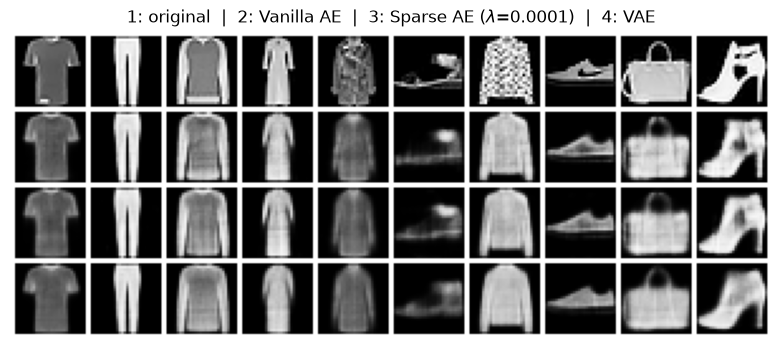

In [46]:
x_all, y_all = next(iter(test_dl))                       # shuffle=False -> same images every run
pick = [(y_all == c).nonzero()[0].item() for c in range(10)]
x_pick = x_all[pick].to(DEVICE)                          # (10,1,28,28)

ae.eval()
sae_best.eval()
vae.eval()
with torch.no_grad():
    rec_ae  = ae(x_pick)[0].view(-1, 1, 28, 28)
    rec_sae = sae_best(x_pick)[0].view(-1, 1, 28, 28)
    rec_vae = vae.dec(vae.encode(x_pick)[0]).view(-1, 1, 28, 28)  # z = mu: vae(x) would add random noise

mse_ae  = ((rec_ae  - x_pick) ** 2).flatten(1).mean(1)
mse_sae = ((rec_sae - x_pick) ** 2).flatten(1).mean(1)
mse_vae = ((rec_vae - x_pick) ** 2).flatten(1).mean(1)
print(f"{'class':12}{'AE':>9}{'SAE':>9}{'VAE':>9}")
for c in range(10):
    print(f"{CLASSES[c]:12}{mse_ae[c]:9.5f}{mse_sae[c]:9.5f}{mse_vae[c]:9.5f}")

show_grid(torch.cat([x_pick, rec_ae, rec_sae, rec_vae]), nrow=10,
          title=f"1: original  |  2: Vanilla AE  |  3: Sparse AE ($\\lambda$={best_lam})  |  4: VAE",
          path=FIG_DIR / "ae_sae_vae_recon.png")

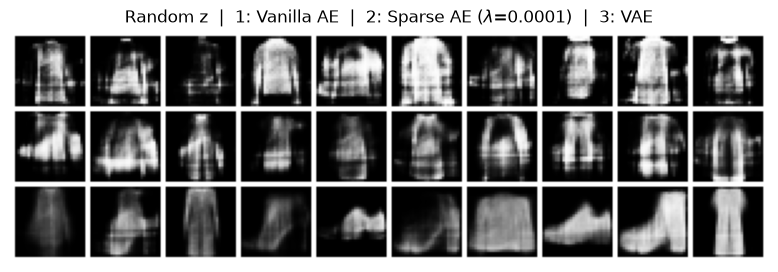

In [ ]:
# decode RANDOM latents
def fitted_gaussian(m):
    z, _ = extract_latents(m, test_dl)   # (7000, 64)
    return z.mean(0), z.std(0)           # per-dimension mean and std, (64,) each

mu_ae,  sd_ae  = fitted_gaussian(ae)
mu_sae, sd_sae = fitted_gaussian(sae_best)

set_seed(42)
with torch.no_grad():
    smp_ae  = ae.dec((mu_ae + sd_ae * torch.randn(10, 64)).to(DEVICE)).view(-1, 1, 28, 28)
    smp_sae = sae_best.dec((mu_sae + sd_sae * torch.randn(10, 64)).to(DEVICE)).view(-1, 1, 28, 28)
    smp_vae = vae.dec(torch.randn(10, 64, device=DEVICE)).view(-1, 1, 28, 28)

show_grid(torch.cat([smp_ae, smp_sae, smp_vae]), nrow=10,
          title=f"Random z  |  1: Vanilla AE  |  2: Sparse AE ($\\lambda$={best_lam})  |  3: VAE",
          path=FIG_DIR / "ae_sae_vae_samples.png")

Generative Adversarial Network (GAN) 

In [48]:
# Generator: noise z (100) -> 256 -> 512 -> 1024 -> 784 pixels
class G_MLP(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, 784), nn.Tanh())
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

# Discriminator: image (784) -> 512 -> 256 -> 1 (riyal or fake)
class D_MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1)) # raw logit: BCEWithLogitsLoss adds the sigmoid
    def forward(self, x):
        return self.net(x)

Z_DIM = 100          # noise size, shared with the DCGAN
GAN_EPOCHS = 50      # GANs need more epochs than the AE family

# loss using BCEWithLogits in train.py

In [49]:
from src.train import train_gan

set_seed(42)
G_gan = G_MLP(Z_DIM).to(DEVICE)
D_gan = D_MLP().to(DEVICE)
print("G parameters:", sum(p.numel() for p in G_gan.parameters()))
print("D parameters:", sum(p.numel() for p in D_gan.parameters()))

# samples of the same 64 noise vectors go to outputs/samples/gan_epXXX.png
hist_gan = train_gan("gan", G_gan, D_gan, train_dl, epochs=GAN_EPOCHS, z_dim=Z_DIM)

G parameters: 1486352
D parameters: 533505
gan ep   1 | D 1.002 | G 0.893 | D(x) 0.81 | D(G(z)) 0.42 | 4.3s
gan ep   2 | D 0.864 | G 1.440 | D(x) 0.80 | D(G(z)) 0.24 | 4.3s
gan ep   3 | D 0.846 | G 1.838 | D(x) 0.75 | D(G(z)) 0.18 | 4.4s
gan ep   4 | D 0.938 | G 1.895 | D(x) 0.69 | D(G(z)) 0.18 | 4.5s
gan ep   5 | D 0.848 | G 2.220 | D(x) 0.72 | D(G(z)) 0.14 | 4.4s
gan ep   6 | D 0.876 | G 2.062 | D(x) 0.71 | D(G(z)) 0.16 | 4.5s
gan ep   7 | D 0.921 | G 1.907 | D(x) 0.69 | D(G(z)) 0.18 | 4.6s
gan ep   8 | D 1.028 | G 1.691 | D(x) 0.66 | D(G(z)) 0.22 | 4.6s
gan ep   9 | D 0.988 | G 1.625 | D(x) 0.66 | D(G(z)) 0.23 | 4.5s
gan ep  10 | D 1.022 | G 1.567 | D(x) 0.66 | D(G(z)) 0.24 | 4.4s
gan ep  11 | D 1.075 | G 1.427 | D(x) 0.63 | D(G(z)) 0.27 | 4.3s
gan ep  12 | D 1.087 | G 1.399 | D(x) 0.63 | D(G(z)) 0.28 | 4.3s
gan ep  13 | D 1.096 | G 1.326 | D(x) 0.62 | D(G(z)) 0.29 | 4.2s
gan ep  14 | D 1.144 | G 1.349 | D(x) 0.61 | D(G(z)) 0.29 | 4.2s
gan ep  15 | D 1.136 | G 1.279 | D(x) 0.60 | D(

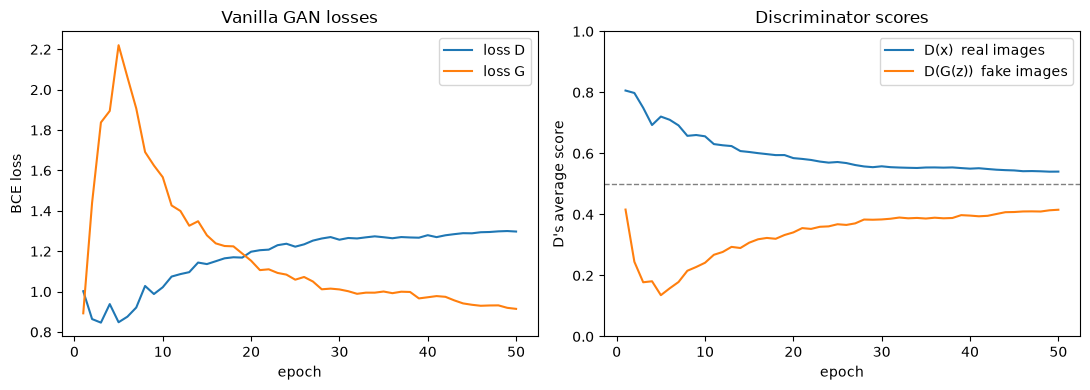

In [50]:
# training curves
# left: the two losses fight each other; right: D's average "real" score for real vs fake images
ep = range(1, len(hist_gan["loss_D"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ep, hist_gan["loss_D"], label="loss D")
ax1.plot(ep, hist_gan["loss_G"], label="loss G")
ax1.set_xlabel("epoch"); ax1.set_ylabel("BCE loss"); ax1.set_title("Vanilla GAN losses"); ax1.legend()

ax2.plot(ep, hist_gan["D_real"], label="D(x)  real images")
ax2.plot(ep, hist_gan["D_fake"], label="D(G(z))  fake images")
ax2.axhline(0.5, color="gray", ls="--", lw=1)         # 0.5 = D can't tell real from fake (ideal end point)
ax2.set_ylim(0, 1)
ax2.set_xlabel("epoch"); ax2.set_ylabel("D's average score"); ax2.set_title("Discriminator scores"); ax2.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "gan_loss.png", dpi=300, bbox_inches="tight")
plt.show()

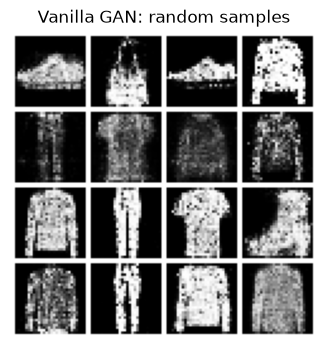

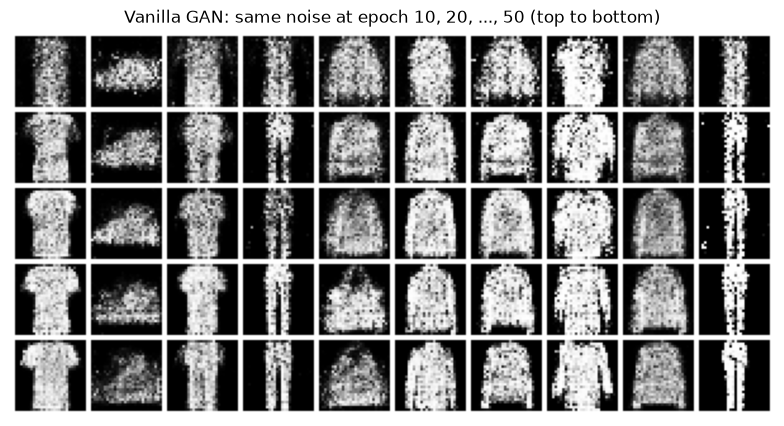

train time/epoch: 4.49 s | latency: 1.971 ms / batch 64


In [ ]:
# 16 random samples from the final G (Figure 2 panel), fixed seed so the figure is reproducible
G_gan.eval()
set_seed(42)
with torch.no_grad():
    smp_gan = (G_gan(torch.randn(16, Z_DIM, device=DEVICE)) + 1) / 2   # [-1,1] -> [0,1] for display/metrics
show_grid(smp_gan, nrow=4, title="Vanilla GAN: random samples", path=FIG_DIR / "gan_samples.png")

# training progress: the SAME 10 noise vectors decoded by G at epoch 10, 20, ..., 50 (top to bottom)
set_seed(0)
z_prog = torch.randn(10, Z_DIM, device=DEVICE)
G_tmp = G_MLP(Z_DIM).to(DEVICE).eval()
rows = []
for e in range(10, GAN_EPOCHS + 1, 10):
    G_tmp.load_state_dict(torch.load(CKPT_DIR / f"gan_G_ep{e}.pt", map_location=DEVICE))
    with torch.no_grad():
        rows.append((G_tmp(z_prog) + 1) / 2)
show_grid(torch.cat(rows), nrow=10, title="Vanilla GAN: same noise at epoch 10, 20, ..., 50 (top to bottom)",
          path=FIG_DIR / "gan_progress.png")

# train time/epoch and latency
z64 = torch.randn(64, Z_DIM, device=DEVICE)
lat_gan = latency_ms(lambda: G_gan(z64))
time_gan = np.mean(hist_gan["epoch_time"])
print(f"train time/epoch: {time_gan:.2f} s | latency: {lat_gan:.3f} ms / batch 64")

In [ ]:
# mode-collapse check: let the trained MLP classifier label 5,000 GAN samples
set_seed(42)
with torch.no_grad():
    fake = torch.cat([(G_gan(torch.randn(500, Z_DIM, device=DEVICE)) + 1) / 2 for _ in range(10)])
    pred = model(fake)[0].argmax(1).cpu()
share = torch.bincount(pred, minlength=10).float() / len(pred)

for c in range(10):
    print(f"{CLASSES[c]:12} {share[c]:6.1%}  " + "#" * int(share[c] * 100))

T-shirt/top   14.6%  ##############
Trouser        9.2%  #########
Pullover      12.2%  ############
Dress         11.2%  ###########
Coat           6.0%  #####
Sandal         6.8%  ######
Shirt         13.8%  #############
Sneaker        9.3%  #########
Bag            8.7%  ########
Ankle boot     8.2%  ########


Deep Convolutional GAN (DCGAN) 

In [ ]:
# Generator: noise z (100) -> 128 maps of 7x7 -> 64 maps of 14x14 -> 1 image of 28x28 in [-1, 1]
class G_DC(nn.Module):
    def __init__(self, z_dim=100, ch=64):
        super().__init__()
        self.ch = ch
        self.fc = nn.Sequential(
            nn.Linear(z_dim, ch * 2 * 7 * 7), nn.BatchNorm1d(ch * 2 * 7 * 7), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(ch * 2, ch, 4, 2, 1), nn.BatchNorm2d(ch), nn.ReLU(),   # 7x7   -> 14x14
            nn.ConvTranspose2d(ch, 1, 4, 2, 1), nn.Tanh())                           # 14x14 -> 28x28
    def forward(self, z):
        return self.net(self.fc(z).view(-1, self.ch * 2, 7, 7))

# Discriminator: image 28x28 -> 64 maps of 14x14 -> 128 maps of 7x7 -> 1 score (raw logit)
class D_DC(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, ch, 4, 2, 1), nn.LeakyReLU(0.2),                              # 28x28 -> 14x14 (no BN on input layer)
            nn.Conv2d(ch, ch * 2, 4, 2, 1), nn.BatchNorm2d(ch * 2), nn.LeakyReLU(0.2), # 14x14 -> 7x7
            nn.Flatten(), nn.Linear(ch * 2 * 7 * 7, 1))
    def forward(self, x):
        return self.net(x)

print(G_DC(Z_DIM)(torch.randn(2, Z_DIM)).shape)        # (2, 1, 28, 28)
print(D_DC()(torch.randn(2, 1, 28, 28)).shape)         # (2, 1)

torch.Size([2, 1, 28, 28])
torch.Size([2, 1])


In [ ]:
# train
set_seed(42)
G_dc = G_DC(Z_DIM).to(DEVICE)
D_dc = D_DC().to(DEVICE)
print("G parameters:", sum(p.numel() for p in G_dc.parameters()))
print("D parameters:", sum(p.numel() for p in D_dc.parameters()))

# samples of the same 64 noise vectors go to outputs/samples/dcgan_epXXX.png
hist_dc = train_gan("dcgan", G_dc, D_dc, train_dl, epochs=GAN_EPOCHS, z_dim=Z_DIM)

G parameters: 778305
D parameters: 138817
dcgan ep   1 | D 0.385 | G 2.473 | D(x) 0.85 | D(G(z)) 0.13 | 9.5s
dcgan ep   2 | D 0.285 | G 2.507 | D(x) 0.87 | D(G(z)) 0.11 | 8.7s
dcgan ep   3 | D 0.339 | G 2.605 | D(x) 0.86 | D(G(z)) 0.12 | 8.7s
dcgan ep   4 | D 0.346 | G 2.421 | D(x) 0.86 | D(G(z)) 0.13 | 8.5s
dcgan ep   5 | D 0.431 | G 2.310 | D(x) 0.83 | D(G(z)) 0.16 | 8.6s
dcgan ep   6 | D 0.498 | G 2.082 | D(x) 0.80 | D(G(z)) 0.18 | 8.9s
dcgan ep   7 | D 0.540 | G 1.965 | D(x) 0.79 | D(G(z)) 0.20 | 8.6s
dcgan ep   8 | D 0.580 | G 1.909 | D(x) 0.78 | D(G(z)) 0.21 | 8.8s
dcgan ep   9 | D 0.606 | G 1.847 | D(x) 0.77 | D(G(z)) 0.22 | 8.7s
dcgan ep  10 | D 0.626 | G 1.807 | D(x) 0.76 | D(G(z)) 0.22 | 8.8s
dcgan ep  11 | D 0.629 | G 1.787 | D(x) 0.76 | D(G(z)) 0.23 | 8.8s
dcgan ep  12 | D 0.635 | G 1.798 | D(x) 0.76 | D(G(z)) 0.23 | 8.5s
dcgan ep  13 | D 0.629 | G 1.815 | D(x) 0.76 | D(G(z)) 0.22 | 8.6s
dcgan ep  14 | D 0.625 | G 1.834 | D(x) 0.76 | D(G(z)) 0.22 | 8.6s
dcgan ep  15 | D 0.6

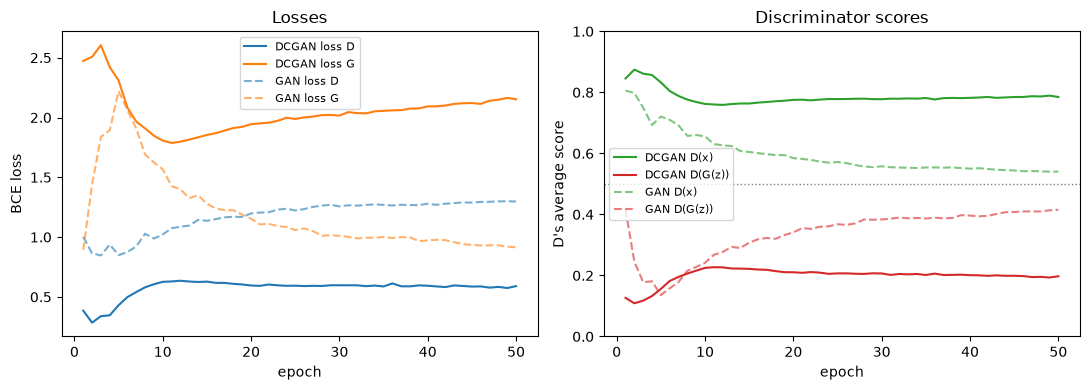

In [ ]:
# training curves: DCGAN and Vanilla GAN
ep    = range(1, len(hist_dc["loss_D"]) + 1)
ep_gan = range(1, len(hist_gan["loss_D"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ep, hist_dc["loss_D"], color="C0", label="DCGAN loss D")
ax1.plot(ep, hist_dc["loss_G"], color="C1", label="DCGAN loss G")
ax1.plot(ep_gan, hist_gan["loss_D"], color="C0", ls="--", alpha=0.6, label="GAN loss D")
ax1.plot(ep_gan, hist_gan["loss_G"], color="C1", ls="--", alpha=0.6, label="GAN loss G")
ax1.set_xlabel("epoch"); ax1.set_ylabel("BCE loss"); ax1.set_title("Losses"); ax1.legend(fontsize=8)

ax2.plot(ep, hist_dc["D_real"], color="C2", label="DCGAN D(x)")
ax2.plot(ep, hist_dc["D_fake"], color="C3", label="DCGAN D(G(z))")
ax2.plot(ep_gan, hist_gan["D_real"], color="C2", ls="--", alpha=0.6, label="GAN D(x)")
ax2.plot(ep_gan, hist_gan["D_fake"], color="C3", ls="--", alpha=0.6, label="GAN D(G(z))")
ax2.axhline(0.5, color="gray", ls=":", lw=1)            # 0.5 = D can't tell real from fake
ax2.set_ylim(0, 1)
ax2.set_xlabel("epoch"); ax2.set_ylabel("D's average score"); ax2.set_title("Discriminator scores"); ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "dcgan_loss.png", dpi=300, bbox_inches="tight")
plt.show()

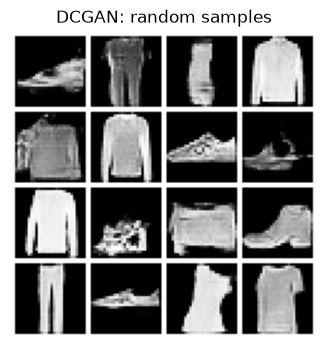

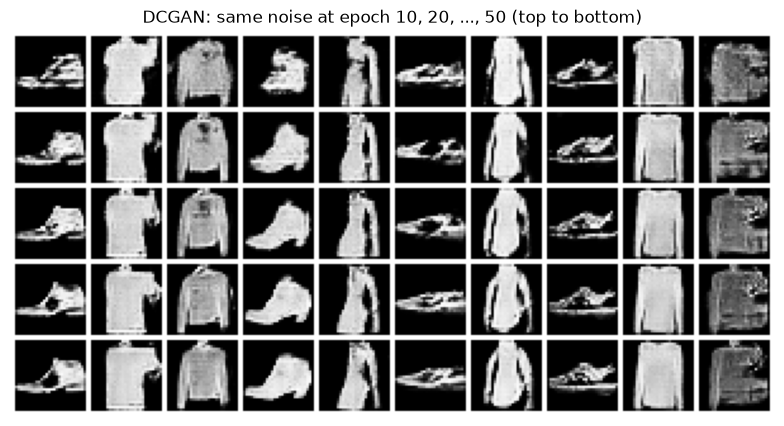

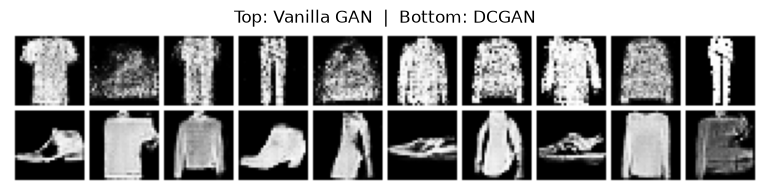

              time/epoch (s)  latency (ms/64)
Vanilla GAN             4.49            1.971
DCGAN                   8.63            1.622


In [ ]:
# 16 random samples from the final G
G_dc.eval()
set_seed(42)
with torch.no_grad():
    smp_dc = (G_dc(torch.randn(16, Z_DIM, device=DEVICE)) + 1) / 2   # [-1,1] -> [0,1]
show_grid(smp_dc, nrow=4, title="DCGAN: random samples", path=FIG_DIR / "dcgan_samples.png")

# training progress: the same 10 noise vectors at epoch 10, 20, ..., 50
G_tmp = G_DC(Z_DIM).to(DEVICE).eval()
rows = []
for e in range(10, GAN_EPOCHS + 1, 10):
    G_tmp.load_state_dict(torch.load(CKPT_DIR / f"dcgan_G_ep{e}.pt", map_location=DEVICE))
    with torch.no_grad():
        rows.append((G_tmp(z_prog) + 1) / 2)
show_grid(torch.cat(rows), nrow=10, title="DCGAN: same noise at epoch 10, 20, ..., 50 (top to bottom)",
          path=FIG_DIR / "dcgan_progress.png")

# GAN vs DCGAN, 10 samples each from the same noise vectors
with torch.no_grad():
    row_gan = (G_gan(z_prog) + 1) / 2
    row_dc  = (G_dc(z_prog) + 1) / 2
show_grid(torch.cat([row_gan, row_dc]), nrow=10, title="Top: Vanilla GAN  |  Bottom: DCGAN",
          path=FIG_DIR / "gan_vs_dcgan.png")

# train time/epoch and latency
lat_dc = latency_ms(lambda: G_dc(z64))
time_dc = np.mean(hist_dc["epoch_time"])
print(f"{'':12}{'time/epoch (s)':>16}{'latency (ms/64)':>17}")
print(f"{'Vanilla GAN':12}{time_gan:16.2f}{lat_gan:17.3f}")
print(f"{'DCGAN':12}{time_dc:16.2f}{lat_dc:17.3f}")

In [ ]:
# mode-collapse check, GAN vs DCGAN: the MLP classifier labels 5,000 samples from each generator
def class_share(G, n=5000, batch=500):
    G.eval()
    set_seed(42)
    with torch.no_grad():
        fake = torch.cat([(G(torch.randn(batch, Z_DIM, device=DEVICE)) + 1) / 2 for _ in range(n // batch)])
        pred = model(fake)[0].argmax(1).cpu()
    return torch.bincount(pred, minlength=10).float() / len(pred)

share_gan, share_dc = class_share(G_gan), class_share(G_dc)
print(f"{'class':12}{'GAN':>8}{'DCGAN':>8}")
for c in range(10):
    print(f"{CLASSES[c]:12}{share_gan[c]:8.1%}{share_dc[c]:8.1%}")
print(f"{'max - min':12}{share_gan.max() - share_gan.min():8.1%}{share_dc.max() - share_dc.min():8.1%}")

class            GAN   DCGAN
T-shirt/top    14.6%   10.5%
Trouser         9.2%   10.3%
Pullover       12.2%   11.7%
Dress          11.2%    9.1%
Coat            6.0%   10.6%
Sandal          6.8%    9.8%
Shirt          13.8%    7.4%
Sneaker         9.3%    8.6%
Bag             8.7%   11.6%
Ankle boot      8.2%   10.5%
max - min       8.6%    4.2%


Denoising Diffusion Probabilistic Models (DDPM)

In [58]:
metrics = [
    "Arsitektur Model",
    "Dim Laten",
    "Training Time / Epoch (s)",
    "Latency (ms / batch 64)",
    "Test MSE",
    "Test PSNR (dB)",
    "FID Score",
    "Kestabilan Training"
]